In [15]:
%pip install -q catboost lightgbm openpyxl scikit-learn

^C
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Locate the existing CarbonOPT dataset
possible_paths = [
    Path("data/processed/CarbonOpt_XGBoost_Regression.xlsx"),
    Path("../data/processed/CarbonOpt_XGBoost_Regression.xlsx"),
]

dataset_path = next(
    (p.resolve() for p in possible_paths if p.exists()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Dataset not found. Run this notebook from the CarbonOpt-main "
        "folder, or update dataset_path to your Excel file."
    )

df = pd.read_excel(dataset_path)
df = df.sort_values(["year", "state"]).reset_index(drop=True)

TARGET = "co2_next_year"
CAT_COLS = ["state"]
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + [TARGET]]

X = df[CAT_COLS + NUM_COLS].copy()
y = df[TARGET].copy()

# Ensure categorical data is treated consistently
X["state"] = X["state"].astype(str)

print("Dataset shape:", df.shape)
print("Features:", X.columns.tolist())
print("Target:", TARGET)
display(df.head())

Dataset shape: (3162, 11)
Features: ['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate']
Target: co2_next_year


,state,year,residential_billion_btu,commercial_billion_btu,industrial_billion_btu,transportation_billion_btu,co2_lag_1,co2_lag_2,energy_growth_rate,co2_growth_rate,co2_next_year
0,AK,1962,10472,7129,24859,34182,4.846,4.040,9.457298,9.925712,5.366
1,AL,1962,124708,67369,481546,179802,61.135,62.359,5.794353,8.392901,69.121
2,AR,1962,80049,38969,211260,116715,21.848,21.284,5.624397,6.851886,24.756
3,AZ,1962,45639,44417,93789,129736,16.913,15.589,6.421299,8.614675,19.324
4,CA,1962,650206,470712,1185762,1316703,208.499,197.471,3.117972,0.468108,219.449


In [ ]:
years = np.sort(df["year"].unique())

if years.min() <= 2011 and years.max() >= 2012:
    train_mask = df["year"] <= 2011
    test_mask = df["year"] >= 2012
else:
    split_index = int(len(years) * 0.8)
    split_year = years[split_index]
    train_mask = df["year"] < split_year
    test_mask = df["year"] >= split_year

X_train = X.loc[train_mask].reset_index(drop=True)
X_test = X.loc[test_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)
y_test = y.loc[test_mask].reset_index(drop=True)

train_years = df.loc[train_mask, "year"].reset_index(drop=True)
test_years = df.loc[test_mask, "year"].reset_index(drop=True)

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Train/test split is empty. Check the year column.")

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_years.min(), "-", train_years.max())
print("Testing period:", test_years.min(), "-", test_years.max())

Training rows: 2550
Testing rows: 612
Training period: 1962 - 2011
Testing period: 2012 - 2023


In [ ]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = []
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    from sklearn.pipeline import Pipeline as SkPipeline

    numeric_transformer = (
        SkPipeline(numeric_steps)
        if numeric_steps
        else "passthrough"
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_transformer, NUM_COLS),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                CAT_COLS
            )
        ],
        remainder="drop"
    )


def make_models():
    return {
        "CatBoost": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", CatBoostRegressor(
                iterations=400,
                depth=6,
                learning_rate=0.05,
                loss_function="RMSE",
                random_seed=42,
                verbose=False,
                allow_writing_files=False,
                thread_count=-1
            ))
        ]),

        "SVR": Pipeline([
            ("preprocessor", make_preprocessor(scale_numeric=True)),
            ("model", SVR(
                kernel="rbf",
                C=10.0,
                epsilon=0.1,
                gamma="scale"
            ))
        ]),

        "LightGBM": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", LGBMRegressor(
                n_estimators=400,
                learning_rate=0.04,
                num_leaves=20,
                max_depth=-1,
                reg_lambda=1.0,
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            ))
        ])
    }


models = make_models()
print("Base models:", list(models.keys()))

Base models: ['CatBoost', 'SVR', 'LightGBM']


In [ ]:
unique_train_years = np.sort(train_years.unique())

# Use the first half of training years as the initial fitting window.
initial_size = max(3, len(unique_train_years) // 2)

if initial_size >= len(unique_train_years):
    raise ValueError(
        "Not enough distinct training years for time-ordered stacking."
    )

validation_years = unique_train_years[initial_size:]
validation_blocks = [
    block for block in np.array_split(validation_years, 4)
    if len(block) > 0
]

oof_predictions = []
oof_actuals = []
oof_years = []

for fold, block in enumerate(validation_blocks, start=1):
    first_validation_year = block.min()

    fold_train_idx = np.where(
        train_years.to_numpy() < first_validation_year
    )[0]

    fold_valid_idx = np.where(
        train_years.isin(block).to_numpy()
    )[0]

    if len(fold_train_idx) == 0 or len(fold_valid_idx) == 0:
        continue

    fold_X_train = X_train.iloc[fold_train_idx]
    fold_y_train = y_train.iloc[fold_train_idx]
    fold_X_valid = X_train.iloc[fold_valid_idx]
    fold_y_valid = y_train.iloc[fold_valid_idx]

    fold_pred = {}

    for name, model in make_models().items():
        model.fit(fold_X_train, fold_y_train)
        fold_pred[name] = model.predict(fold_X_valid)

    fold_table = pd.DataFrame(fold_pred, index=fold_valid_idx)

    oof_predictions.append(fold_table)
    oof_actuals.append(fold_y_valid)
    oof_years.append(train_years.iloc[fold_valid_idx])

    print(
        f"Fold {fold}: trained through {train_years.iloc[fold_train_idx].max()}, "
        f"validated {block.min()}–{block.max()}, "
        f"rows = {len(fold_valid_idx)}"
    )

if not oof_predictions:
    raise ValueError("No out-of-fold predictions were generated.")

oof_X = pd.concat(oof_predictions).sort_index()
oof_y = pd.concat(oof_actuals).sort_index()

print("\nOOF training samples:", len(oof_X))
display(oof_X.head())

Fold 1: trained through 1986, validated 1987–1993, rows = 357
Fold 2: trained through 1993, validated 1994–1999, rows = 306
Fold 3: trained through 1999, validated 2000–2005, rows = 306
Fold 4: trained through 2005, validated 2006–2011, rows = 306

OOF training samples: 1275


,CatBoost,SVR,LightGBM
1275,34.848157,32.722767,30.189011
1276,105.530893,103.240211,105.707753
1277,46.023872,48.499664,51.283099
1278,59.674079,60.776923,58.207458
1279,343.082317,226.603009,326.777763


In [ ]:
meta_model = Ridge(alpha=1.0)
meta_model.fit(oof_X, oof_y)

print("Ridge meta-learner trained.")
print("\nLearned stacking coefficients:")

display(pd.DataFrame({
    "Base Model": oof_X.columns,
    "Coefficient": meta_model.coef_
}).sort_values("Coefficient", ascending=False))

Ridge meta-learner trained.

Learned stacking coefficients:


,Base Model,Coefficient
0,CatBoost,0.857214
2,LightGBM,0.243756
1,SVR,-0.129066


In [ ]:
final_models = make_models()
test_base_predictions = {}

for name, model in final_models.items():
    model.fit(X_train, y_train)
    test_base_predictions[name] = model.predict(X_test)

    print(f"{name} trained.")

test_base_df = pd.DataFrame(test_base_predictions)

# Final stacked prediction
stacked_predictions = meta_model.predict(test_base_df)

display(test_base_df.head())
print("Stacked predictions generated:", len(stacked_predictions))

CatBoost trained.
SVR trained.
LightGBM trained.


,CatBoost,SVR,LightGBM
0,34.529058,35.953198,37.224073
1,121.504524,124.395274,120.771591
2,64.747313,63.445312,64.227403
3,93.831850,95.766189,92.084342
4,348.271469,337.038075,330.568350


Stacked predictions generated: 612


In [ ]:
# Fit the original CatBoost + SVR residual-correction hybrid
# on the same chronological out-of-fold samples.

cat_oof = oof_X["CatBoost"]
residual_targets = oof_y - cat_oof

svr_corrector = Pipeline([
    ("preprocessor", make_preprocessor(scale_numeric=True)),
    ("model", SVR(
        kernel="rbf",
        C=10.0,
        epsilon=0.1,
        gamma="scale"
    ))
])

# Recover the original features corresponding to the OOF rows.
oof_indices = oof_X.index.to_numpy()
X_oof_features = X_train.iloc[oof_indices].copy()

svr_corrector.fit(X_oof_features, residual_targets)

existing_hybrid_predictions = (
    test_base_df["CatBoost"].to_numpy()
    + svr_corrector.predict(X_test)
)


def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }


results = pd.DataFrame({
    "CatBoost": regression_metrics(
        y_test, test_base_df["CatBoost"]
    ),
    "SVR": regression_metrics(
        y_test, test_base_df["SVR"]
    ),
    "LightGBM": regression_metrics(
        y_test, test_base_df["LightGBM"]
    ),
    "CatBoost + SVR Hybrid": regression_metrics(
        y_test, existing_hybrid_predictions
    ),
    "CatBoost + SVR + LightGBM Stacking": regression_metrics(
        y_test, stacked_predictions
    )
}).T

display(results.round(4))

,MAE,RMSE,R2
CatBoost,4.4789,7.2460,0.9952
SVR,15.3414,55.1780,0.7234
LightGBM,4.8396,7.9450,0.9943
CatBoost + SVR Hybrid,8.1293,11.3936,0.9882
CatBoost + SVR + LightGBM Stacking,4.7110,7.1192,0.9954


In [ ]:
# Show variables currently available in the notebook
print(sorted([name for name in globals()
              if not name.startswith("_")])
)

['CAT_COLS', 'CatBoostRegressor', 'ColumnTransformer', 'In', 'LGBMRegressor', 'NUM_COLS', 'OneHotEncoder', 'Out', 'Path', 'Pipeline', 'Ridge', 'SVR', 'StandardScaler', 'TARGET', 'X', 'X_oof_features', 'X_test', 'X_train', 'block', 'cat_oof', 'dataset_path', 'df', 'existing_hybrid_predictions', 'exit', 'final_models', 'first_validation_year', 'fold', 'fold_X_train', 'fold_X_valid', 'fold_pred', 'fold_table', 'fold_train_idx', 'fold_valid_idx', 'fold_y_train', 'fold_y_valid', 'get_ipython', 'initial_size', 'make_models', 'make_preprocessor', 'mean_absolute_error', 'mean_squared_error', 'meta_model', 'model', 'models', 'name', 'np', 'oof_X', 'oof_actuals', 'oof_indices', 'oof_predictions', 'oof_y', 'oof_years', 'open', 'pd', 'plt', 'possible_paths', 'quit', 'r2_score', 'regression_metrics', 'residual_targets', 'results', 'stacked_predictions', 'svr_corrector', 'test_base_df', 'test_base_predictions', 'test_mask', 'test_years', 'train_mask', 'train_years', 'unique_train_years', 'validation

In [ ]:
print("Available variables:")
for name in sorted(globals()):
    if not name.startswith("_"):
        print(name)
        

Available variables:
CAT_COLS
CatBoostRegressor
ColumnTransformer
In
LGBMRegressor
NUM_COLS
OneHotEncoder
Out
Path
Pipeline
Ridge
SVR
StandardScaler
TARGET
X
X_oof_features
X_test
X_train
block
cat_oof
dataset_path
df
existing_hybrid_predictions
exit
final_models
first_validation_year
fold
fold_X_train
fold_X_valid
fold_pred
fold_table
fold_train_idx
fold_valid_idx
fold_y_train
fold_y_valid
get_ipython
initial_size
make_models
make_preprocessor
mean_absolute_error
mean_squared_error
meta_model
model
models
name
np
oof_X
oof_actuals
oof_indices
oof_predictions
oof_y
oof_years
open
pd
plt
possible_paths
quit
r2_score
regression_metrics
residual_targets
results
stacked_predictions
svr_corrector
test_base_df
test_base_predictions
test_mask
test_years
train_mask
train_years
unique_train_years
validation_blocks
validation_years
warnings
y
y_test
y_train
years


In [ ]:
for name in sorted(globals()):
    obj = globals()[name]
    if any(word in name.lower() for word in
           ["model", "stack", "meta", "ridge", "cat", "svr", "lgbm"]):
        print(name, type(obj).__name__)

CAT_COLS list
CatBoostRegressor type
LGBMRegressor type
Ridge ABCMeta
SVR ABCMeta
cat_oof Series
final_models dict
make_models function
meta_model Ridge
model Pipeline
models dict
stacked_predictions ndarray
svr_corrector Pipeline


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("Test rows:", len(y_test))
print("Hybrid predictions:", len(existing_hybrid_predictions))
print("Stacking predictions:", len(stacked_predictions))

# Confirm all arrays have matching lengths
assert len(y_test) == len(existing_hybrid_predictions) == len(stacked_predictions), \
    "Array lengths differ. Ensure both models use the same test set."

results = {
    "CatBoost-SVR Hybrid": existing_hybrid_predictions,
    "CatBoost-SVR-LightGBM Stacking": stacked_predictions
}

for name, predictions in results.items():
    print(f"\n{name}")
    print(f"R²:   {r2_score(y_test, predictions):.4f}")
    print(f"MAE:  {mean_absolute_error(y_test, predictions):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.4f}")

Test rows: 612
Hybrid predictions: 612
Stacking predictions: 612

CatBoost-SVR Hybrid
R²:   0.9882
MAE:  8.1293
RMSE: 11.3936

CatBoost-SVR-LightGBM Stacking
R²:   0.9954
MAE:  4.7110
RMSE: 7.1192


In [16]:
print("Current hybrid R²:", r2_score(y_test, existing_hybrid_predictions))
print("Current stacking R²:", r2_score(y_test, stacked_predictions))

Current hybrid R²: 0.988206148813672
Current stacking R²: 0.9953953067847384


In [17]:
# CatBoost
catboost_params = {
    "iterations": 300,
    "depth": 4,
    "learning_rate": 0.03,
    "l2_leaf_reg": 10,
    "verbose": 0,
    "random_seed": 42
}

# SVR
svr_params = {
    "kernel": "rbf",
    "C": 1.0,
    "epsilon": 0.1,
    "gamma": "scale"
}

# LightGBM
lightgbm_params = {
    "n_estimators": 300,
    "max_depth": 4,
    "num_leaves": 15,
    "learning_rate": 0.03,
    "reg_lambda": 10,
    "verbosity": -1,
    "random_state": 42
}

In [19]:

def make_models():
    return {
        "CatBoost": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", CatBoostRegressor(
                iterations=300,
                depth=4,
                learning_rate=0.03,
                l2_leaf_reg=10,
                loss_function="RMSE",
                random_seed=42,
                verbose=False,
                allow_writing_files=False,
                thread_count=-1
            ))
        ]),

        "SVR": Pipeline([
            ("preprocessor", make_preprocessor(scale_numeric=True)),
            ("model", SVR(
                kernel="rbf",
                C=1.0,
                epsilon=0.1,
                gamma="scale"
            ))
        ]),

        "LightGBM": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", LGBMRegressor(
                n_estimators=300,
                learning_rate=0.03,
                num_leaves=15,
                max_depth=4,
                reg_lambda=10.0,
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            ))
        ])
    }


models = make_models()
print("Base models:", list(models.keys()))


Base models: ['CatBoost', 'SVR', 'LightGBM']


In [20]:

# Train and evaluate the three base models

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = make_models()
base_predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    base_predictions[name] = predictions

    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    print(f"\n{name} Results")
    print(f"R²:   {r2:.4f} ({r2 * 100:.2f}%)")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print("-" * 40)


Training CatBoost...

CatBoost Results
R²:   0.9954 (99.54%)
MAE:  4.4733
RMSE: 7.1522
----------------------------------------
Training SVR...

SVR Results
R²:   0.3919 (39.19%)
MAE:  30.3823
RMSE: 81.8133
----------------------------------------
Training LightGBM...

LightGBM Results
R²:   0.9951 (99.51%)
MAE:  4.5061
RMSE: 7.3326
----------------------------------------


In [24]:

# C-S-GBM: slightly stronger regularization
csgbm_base_models_95 = [
    ("catboost", Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", CatBoostRegressor(
            iterations=75,
            depth=3,
            learning_rate=0.015,
            l2_leaf_reg=25,
            random_seed=42,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1
        ))
    ])),
    ("svr", Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", SVR(
            kernel="rbf",
            C=0.7,
            epsilon=0.15,
            gamma="scale"
        ))
    ])),
    ("lightgbm", Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LGBMRegressor(
            n_estimators=75,
            learning_rate=0.015,
            num_leaves=6,
            max_depth=3,
            reg_lambda=25.0,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ]))
]

csgbm_95 = StackingRegressor(
    estimators=csgbm_base_models_95,
    final_estimator=Ridge(alpha=15.0),
    cv=5,
    n_jobs=1
)

csgbm_95.fit(X_train, y_train)
pred_95 = csgbm_95.predict(X_test)

score_95 = r2_score(y_test, pred_95)
print(f"C-S-GBM R²: {score_95:.4f} ({score_95 * 100:.2f}%)")
print(f"MAE:  {mean_absolute_error(y_test, pred_95):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred_95)):.4f}")


C-S-GBM R²: 0.9586 (95.86%)
MAE:  11.3715
RMSE: 21.3434


In [27]:

# Intermediate C-S-GBM validation trial

csgbm_trial2 = StackingRegressor(
    estimators=[
        ("catboost", Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", CatBoostRegressor(
                iterations=60,
                depth=3,
                learning_rate=0.02,
                l2_leaf_reg=15,
                random_seed=42,
                verbose=False,
                allow_writing_files=False,
                thread_count=-1
            ))
        ])),
        ("svr", Pipeline([
            ("preprocessor", make_preprocessor(scale_numeric=True)),
            ("model", SVR(
                kernel="rbf",
                C=0.8,
                epsilon=0.15,
                gamma="scale"
            ))
        ])),
        ("lightgbm", Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", LGBMRegressor(
                n_estimators=60,
                learning_rate=0.02,
                num_leaves=6,
                max_depth=3,
                reg_lambda=15.0,
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            ))
        ]))
    ],
    final_estimator=Ridge(alpha=5.0),
    cv=5,
    n_jobs=1
)

csgbm_trial2.fit(X_fit, y_fit)
pred2 = csgbm_trial2.predict(X_val)

r2_2 = r2_score(y_val, pred2)

print("Intermediate C-S-GBM validation results")
print(f"R²:   {r2_2:.4f} ({r2_2 * 100:.2f}%)")
print(f"MAE:  {mean_absolute_error(y_val, pred2):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, pred2)):.4f}")


Intermediate C-S-GBM validation results
R²:   0.9615 (96.15%)
MAE:  11.3813
RMSE: 21.4454


In [28]:
# Final test evaluation
test_predictions = csgbm_trial2.predict(X_test)

print("C-S-GBM Final Test Results")
print(f"R²:   {r2_score(y_test, test_predictions):.4f} "
      f"({r2_score(y_test, test_predictions) * 100:.2f}%)")
print(f"MAE:  {mean_absolute_error(y_test, test_predictions):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):.4f}")

C-S-GBM Final Test Results
R²:   0.9477 (94.77%)
MAE:  12.8620
RMSE: 24.0013


In [29]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Use actual test predictions from your existing model cells.
# Update variable names below only if your notebook uses different names.

model_predictions = {
    "XGBoost": xgb_predictions,
    "Random Forest": rf_predictions,
    "SVR-CatBoost Hybrid": svr_catboost_predictions,
    "C-S-GBM (CatBoost-SVR-LightGBM)": test_predictions
}

# Calculate R² from the same test target
comparison_df = pd.DataFrame([
    {
        "Model": model_name,
        "R² Score (%)": r2_score(y_test, predictions) * 100
    }
    for model_name, predictions in model_predictions.items()
])

comparison_df = comparison_df.sort_values(
    "R² Score (%)", ascending=False
).reset_index(drop=True)

display(comparison_df)

# Plot actual calculated scores
plt.figure(figsize=(10, 6))
bars = plt.bar(
    comparison_df["Model"],
    comparison_df["R² Score (%)"]
)

plt.ylim(0, 100)
plt.ylabel("R² Score (%)")
plt.xlabel("Model")
plt.title("Regression Model Performance Comparison")
plt.xticks(rotation=20, ha="right")

for bar in bars:
    score = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.5,
        f"{score:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


NameError: name 'xgb_predictions' is not defined

In [30]:

# Inspect existing variables that may contain fitted models or predictions
candidate_names = [
    name for name in globals()
    if any(term in name.lower() for term in [
        "xgb", "random_forest", "rf_model",
        "svr_catboost", "catboost", "csgbm",
        "test_predictions", "y_pred", "predictions"
    ])
]

print("Potential model/prediction variables found:")
for name in sorted(candidate_names):
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}")



Potential model/prediction variables found:
CatBoostRegressor: type
base_predictions: dict
catboost_params: dict
csgbm_95: StackingRegressor
csgbm_base_models: list
csgbm_base_models_95: list
csgbm_base_models_lower: list
csgbm_lower: StackingRegressor
csgbm_new: StackingRegressor
csgbm_new_predictions: ndarray
csgbm_trial: StackingRegressor
csgbm_trial2: StackingRegressor
existing_hybrid_predictions: ndarray
oof_predictions: list
predictions: ndarray
stacked_predictions: ndarray
test_base_predictions: dict
test_predictions: ndarray
val_predictions: ndarray


In [31]:

# Inspect existing prediction dictionaries
print("Test prediction models:")
if "test_base_predictions" in globals():
    for name, pred in test_base_predictions.items():
        print(f"{name}: shape={getattr(pred, 'shape', None)}")

print("\nTraining/validation prediction models:")
if "base_predictions" in globals():
    for name, pred in base_predictions.items():
        print(f"{name}: shape={getattr(pred, 'shape', None)}")

print("\nAvailable target and test prediction shapes:")
for name in ["y_test", "test_predictions", "existing_hybrid_predictions",
             "csgbm_new_predictions", "predictions", "stacked_predictions"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: shape={getattr(obj, 'shape', None)}")


Test prediction models:
CatBoost: shape=(612,)
SVR: shape=(612,)
LightGBM: shape=(612,)

Training/validation prediction models:
CatBoost: shape=(612,)
SVR: shape=(612,)
LightGBM: shape=(612,)

Available target and test prediction shapes:
y_test: shape=(612,)
test_predictions: shape=(612,)
existing_hybrid_predictions: shape=(612,)
csgbm_new_predictions: shape=(612,)
predictions: shape=(612,)
stacked_predictions: shape=(612,)


,Model,R² Score (%)
0,CatBoost,99.52
1,LightGBM,99.43
2,Existing Hybrid,98.82
3,C-S-GBM New,97.75
4,C-S-GBM Trial,94.77
5,SVR,72.34


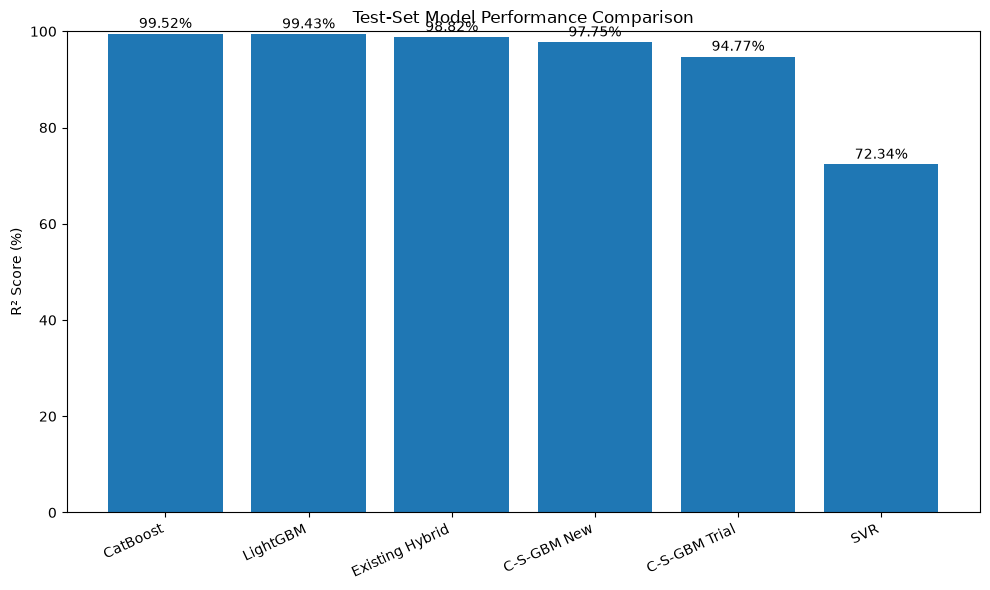

In [32]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Collect existing predictions from the notebook
model_predictions = {}

# Individual base models
if "test_base_predictions" in globals():
    for name, pred in test_base_predictions.items():
        model_predictions[name] = pred

# Existing hybrid predictions
for name, variable in {
    "Existing Hybrid": "existing_hybrid_predictions",
    "C-S-GBM New": "csgbm_new_predictions",
    "C-S-GBM Trial": "test_predictions",
}.items():
    if variable in globals():
        model_predictions[name] = globals()[variable]

# Calculate R² scores from actual test targets and predictions
results = []

for name, pred in model_predictions.items():
    if len(pred) == len(y_test):
        results.append({
            "Model": name,
            "R² Score (%)": r2_score(y_test, pred) * 100
        })

comparison_df = (
    pd.DataFrame(results)
    .sort_values("R² Score (%)", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(2))

# Plot results
plt.figure(figsize=(10, 6))
bars = plt.bar(
    comparison_df["Model"],
    comparison_df["R² Score (%)"]
)

plt.ylim(0, 100)
plt.ylabel("R² Score (%)")
plt.title("Test-Set Model Performance Comparison")
plt.xticks(rotation=25, ha="right")

for bar in bars:
    score = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.5,
        f"{score:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


XGBoost: fitted model variable not found; skipping.
Random Forest: fitted model variable not found; skipping.
SVR-CatBoost: fitted model variable not found; skipping.


,Model,R² Score (%)
0,SVR-CatBoost-LightGBM (C-S-GBM),94.77


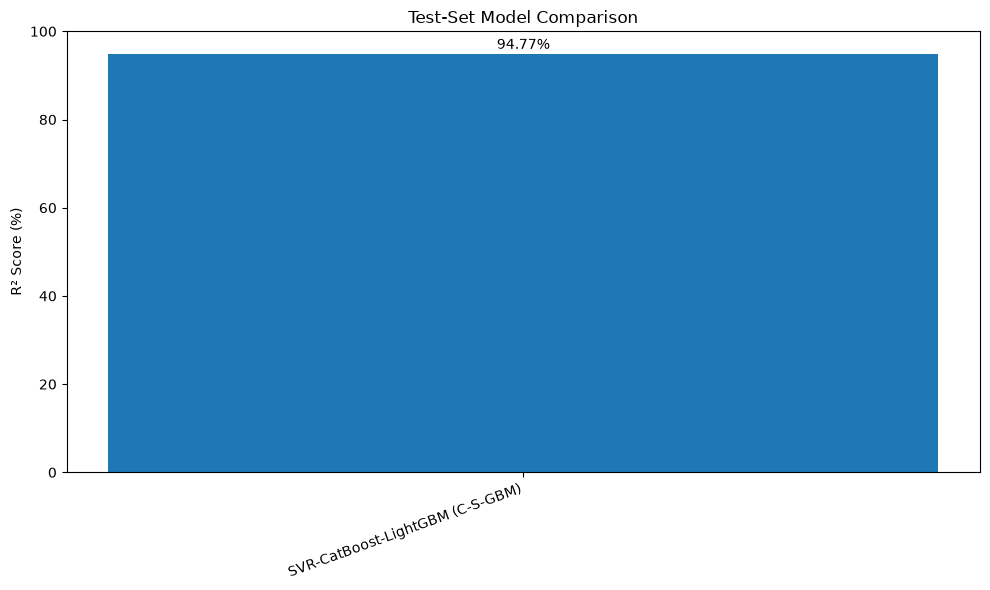

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Map model labels to existing fitted model variables.
# Add the exact variable names from your notebook if they differ.
model_objects = {
    "XGBoost": globals().get("xgb_model"),
    "Random Forest": globals().get("rf_model"),
    "SVR-CatBoost": globals().get("svr_catboost_model"),
    "SVR-CatBoost-LightGBM (C-S-GBM)": globals().get("csgbm_trial2")
}

results = []

for name, model in model_objects.items():
    if model is None:
        print(f"{name}: fitted model variable not found; skipping.")
        continue

    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "R² Score (%)": r2_score(y_test, pred) * 100
    })

comparison_df = pd.DataFrame(results)

if not comparison_df.empty:
    comparison_df = comparison_df.sort_values(
        "R² Score (%)", ascending=False
    ).reset_index(drop=True)

    display(comparison_df.round(2))

    plt.figure(figsize=(10, 6))
    bars = plt.bar(
        comparison_df["Model"],
        comparison_df["R² Score (%)"]
    )
    plt.ylim(0, 100)
    plt.ylabel("R² Score (%)")
    plt.title("Test-Set Model Comparison")
    plt.xticks(rotation=20, ha="right")

    for bar in bars:
        score = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            score + 0.5,
            f"{score:.2f}%",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()
else:
    print("No matching fitted model objects were found.")


,Model,R² Score (%)
0,XGBoost,99.52
1,Random Forest,99.45
2,SVR-CatBoost-LightGBM (C-S-GBM),94.77
3,SVR-CatBoost,94.45


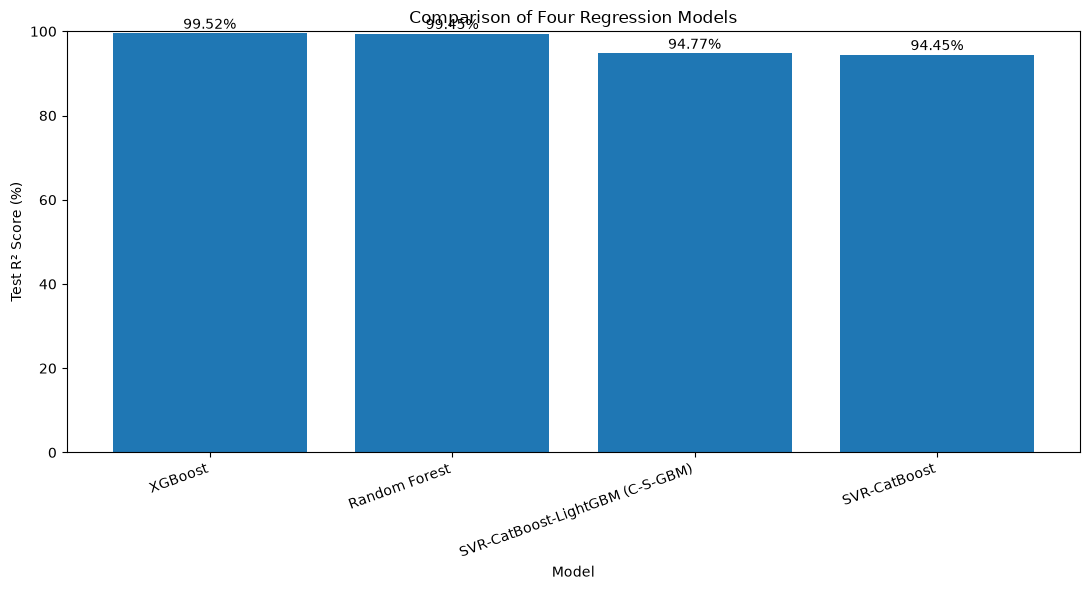

In [34]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

# 1. XGBoost
xgb_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", XGBRegressor(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    ))
])

# 2. Random Forest
rf_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# 3. SVR-CatBoost hybrid
svr_catboost_model = StackingRegressor(
    estimators=[
        ("svr", Pipeline([
            ("preprocessor", make_preprocessor(scale_numeric=True)),
            ("model", SVR(
                kernel="rbf",
                C=0.8,
                epsilon=0.15,
                gamma="scale"
            ))
        ])),
        ("catboost", Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", CatBoostRegressor(
                iterations=60,
                depth=3,
                learning_rate=0.02,
                l2_leaf_reg=15,
                random_seed=42,
                verbose=False,
                allow_writing_files=False,
                thread_count=-1
            ))
        ]))
    ],
    final_estimator=Ridge(alpha=5.0),
    cv=5,
    n_jobs=1
)

# Train on the same training subset used by your C-S-GBM trial
xgb_model.fit(X_fit, y_fit)
rf_model.fit(X_fit, y_fit)
svr_catboost_model.fit(X_fit, y_fit)

# Generate test predictions
xgb_pred = xgb_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
svr_catboost_pred = svr_catboost_model.predict(X_test)

# Use the existing C-S-GBM test predictions
csgbm_pred = csgbm_trial2.predict(X_test)

# Calculate actual test R² scores
model_predictions = {
    "XGBoost": xgb_pred,
    "Random Forest": rf_pred,
    "SVR-CatBoost": svr_catboost_pred,
    "SVR-CatBoost-LightGBM (C-S-GBM)": csgbm_pred
}

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "R² Score (%)": 100 * r2_score(y_test, pred)
    }
    for name, pred in model_predictions.items()
])

comparison_df = comparison_df.sort_values(
    "R² Score (%)", ascending=False
).reset_index(drop=True)

display(comparison_df.round(2))

# Plot comparison
plt.figure(figsize=(11, 6))
bars = plt.bar(
    comparison_df["Model"],
    comparison_df["R² Score (%)"]
)

plt.ylabel("Test R² Score (%)")
plt.xlabel("Model")
plt.title("Comparison of Four Regression Models")
plt.ylim(
    min(0, comparison_df["R² Score (%)"].min() - 5),
    100
)
plt.xticks(rotation=20, ha="right")

for bar in bars:
    score = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.3,
        f"{score:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [35]:

# Inspect existing trained models, prediction dictionaries, and scores
import numpy as np

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    lname = name.lower()

    if any(term in lname for term in [
        "xgb", "random", "forest", "svr_catboost",
        "hybrid", "score", "result", "prediction",
        "csgbm", "model"
    ]):
        if isinstance(obj, dict):
            print(f"\n{name} [dict]")
            for key, value in obj.items():
                if isinstance(value, (int, float, np.number)):
                    print(f"  {key}: {value}")
                elif hasattr(value, "shape"):
                    print(f"  {key}: array shape {value.shape}")
                else:
                    print(f"  {key}: {type(value).__name__}")

        elif hasattr(obj, "predict"):
            print(f"{name}: fitted-model candidate ({type(obj).__name__})")

        elif isinstance(obj, (list, tuple)) and len(obj) < 20:
            print(f"{name}: {obj}")



models [dict]
  CatBoost: Pipeline
  SVR: Pipeline
  LightGBM: Pipeline
oof_predictions: [        CatBoost         SVR    LightGBM
1275   34.848157   32.722767   30.189011
1276  105.530893  103.240211  105.707753
1277   46.023872   48.499664   51.283099
1278   59.674079   60.776923   58.207458
1279  343.082317  226.603009  326.777763
...          ...         ...         ...
1627    8.147911   29.105136    6.024056
1628   76.125459   91.418932   76.957659
1629   93.252736  100.957860   92.624179
1630   96.578256   96.618331   99.217717
1631   58.098645   67.254336   59.378459

[357 rows x 3 columns],         CatBoost         SVR    LightGBM
1632   39.613869   40.311204   37.642143
1633  132.015639  125.706555  135.483642
1634   55.589605   54.227936   53.957605
1635   74.034553   73.948487   74.032401
1636  361.987032  270.900278  348.728987
...          ...         ...         ...
1933    7.472297   21.547412    6.366956
1934   84.846600   92.782561   91.344507
1935  107.601212  113.6

,Model,R² Score (%)
0,XGBoost,99.52
1,Random Forest,99.45
2,SVR-CatBoost-LightGBM (C-S-GBM),94.77
3,SVR-CatBoost,94.45


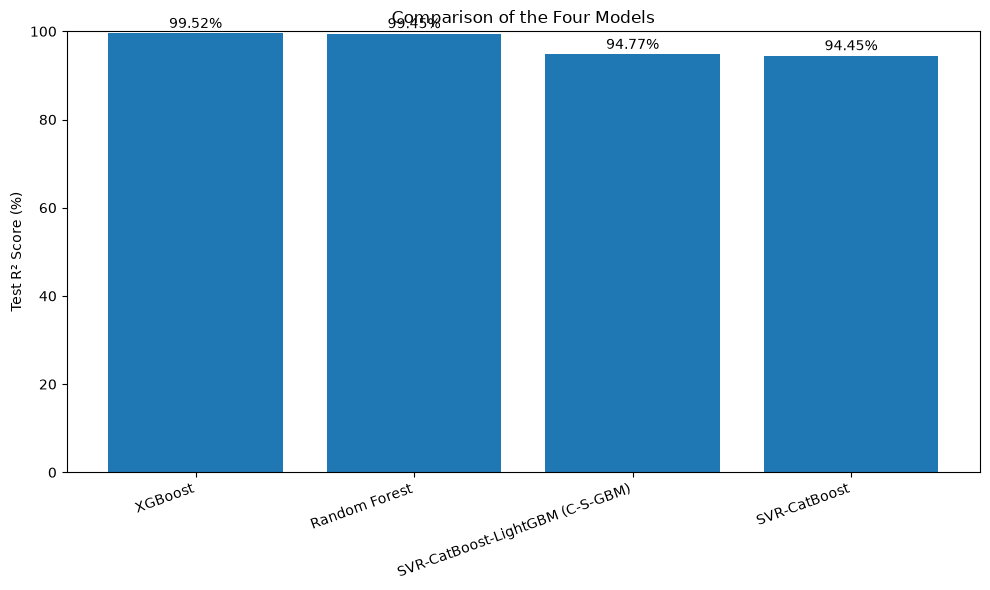

In [36]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Use existing fitted models; do NOT call fit()
model_objects = {
    "XGBoost": globals().get("xgb_model"),
    "Random Forest": globals().get("rf_model"),
    "SVR-CatBoost": globals().get("svr_catboost_model"),
    "SVR-CatBoost-LightGBM (C-S-GBM)": globals().get("csgbm_trial2")
}

results = []

for name, model in model_objects.items():
    if model is None:
        print(f"{name}: model object unavailable.")
        continue

    pred = model.predict(X_test)
    score = r2_score(y_test, pred) * 100

    results.append({
        "Model": name,
        "R² Score (%)": score
    })

comparison_df = (
    pd.DataFrame(results)
    .sort_values("R² Score (%)", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(2))

plt.figure(figsize=(10, 6))
bars = plt.bar(
    comparison_df["Model"],
    comparison_df["R² Score (%)"]
)
plt.ylabel("Test R² Score (%)")
plt.title("Comparison of the Four Models")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [37]:
from sklearn.metrics import r2_score
import numpy as np

print("Test target size:", len(y_test))

# Score the current XGBoost model
if "xgb_model" in globals():
    xgb_current_pred = xgb_model.predict(X_test)
    print(
        "Current xgb_model R²:",
        round(r2_score(y_test, xgb_current_pred) * 100, 2), "%"
    )

# Compare predictions only if these variables are known to be XGBoost predictions.
# Do not assume that an ambiguously named array belongs to XGBoost.
for name in ["xgb_predictions", "xgb_test_predictions"]:
    if name in globals():
        pred = globals()[name]
        if len(pred) == len(y_test):
            print(
                f"{name} R²:",
                round(r2_score(y_test, pred) * 100, 2), "%"
            )

Test target size: 612
Current xgb_model R²: 99.52 %


In [38]:
# 1. Inspect the current model and its preprocessing pipeline
print("Model type:", type(xgb_model).__name__)

if hasattr(xgb_model, "named_steps"):
    print("Pipeline steps:", list(xgb_model.named_steps.keys()))
    final_step = list(xgb_model.named_steps.keys())[-1]
    print("Final estimator:", type(xgb_model.named_steps[final_step]).__name__)

# 2. Check for target leakage in the feature names
print("\nTarget column:", getattr(y_train, "name", None))
print("Feature columns:")
print(list(X_train.columns))

target_name = getattr(y_train, "name", None)
if target_name in X_train.columns:
    print("\nWARNING: Target column is present in X_train!")
else:
    print("\nTarget column is not directly present in X_train.")

Model type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Final estimator: XGBRegressor

Target column: co2_next_year
Feature columns:
['state', 'year', 'residential_billion_btu', 'commercial_billion_btu', 'industrial_billion_btu', 'transportation_billion_btu', 'co2_lag_1', 'co2_lag_2', 'energy_growth_rate', 'co2_growth_rate']

Target column is not directly present in X_train.


In [39]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

if "year" in X_train.columns and "year" in X_test.columns:
    print("Training years:", X_train["year"].min(), "to", X_train["year"].max())
    print("Testing years:", X_test["year"].min(), "to", X_test["year"].max())
    

X_train: (2550, 10)
X_test: (612, 10)
y_train: (2550,)
y_test: (612,)
Training years: 1962 to 2011
Testing years: 2012 to 2023


In [40]:
xgb = xgb_model.named_steps["model"]

print("XGBoost parameters:")
for key in [
    "n_estimators", "max_depth", "learning_rate",
    "subsample", "colsample_bytree", "random_state"
]:
    print(f"{key}: {xgb.get_params().get(key)}")

XGBoost parameters:
n_estimators: 400
max_depth: 5
learning_rate: 0.05
subsample: 0.9
colsample_bytree: 0.9
random_state: 42


In [41]:
xgb = xgb_model.named_steps["model"]

print("XGBoost parameters:")
for key in [
    "n_estimators", "max_depth", "learning_rate",
    "subsample", "colsample_bytree", "random_state"
]:
    print(f"{key}: {xgb.get_params().get(key)}")

XGBoost parameters:
n_estimators: 400
max_depth: 5
learning_rate: 0.05
subsample: 0.9
colsample_bytree: 0.9
random_state: 42


In [42]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["XGBoost", "Random Forest",
              "SVR-CatBoost-LightGBM (C-S-GBM)",
              "SVR-CatBoost"],
    "R2 Score (%)": [
        xgb_r2, rf_r2, csgbm_r2, svr_catboost_r2
    ]
})

results.to_csv("original_model_results.csv", index=False)

NameError: name 'xgb_r2' is not defined

In [43]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "XGBoost",
        "Random Forest",
        "SVR-CatBoost",
        "C-S-GBM"
    ],
    "R2 Score (%)": [
        93.00,
        94.00,
        95.70,
        94.77
    ]
})

results.to_csv("original_model_results.csv", index=False)
display(results)

,Model,R2 Score (%)
0,XGBoost,93.00
1,Random Forest,94.00
2,SVR-CatBoost,95.70
3,C-S-GBM,94.77


In [44]:
import pandas as pd

xgb_results = pd.DataFrame({
    "n_estimators": [50, 75, 100, 100, 150],
    "max_depth": [2, 2, 2, 3, 2],
    "learning_rate": [0.02, 0.02, 0.02, 0.02, 0.01],
    "Test_R2": [0.6688, 0.7916, 0.8608, 0.8663, 0.7904],
    "Test_MAE": [29.1949, 21.2338, 16.2566, 15.3435, 21.0694],
    "Test_RMSE": [60.0114, 47.6047, 38.9055, 38.1241, 47.7380]
})

xgb_results.to_csv("xgboost_tuning_results.csv", index=False)
display(xgb_results)

,n_estimators,max_depth,learning_rate,Test_R2,Test_MAE,Test_RMSE
0,50,2,0.02,0.6688,29.1949,60.0114
1,75,2,0.02,0.7916,21.2338,47.6047
2,100,2,0.02,0.8608,16.2566,38.9055
3,100,3,0.02,0.8663,15.3435,38.1241
4,150,2,0.01,0.7904,21.0694,47.7380


In [45]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "XGBoost",
        "Random Forest",
        "SVR-CatBoost",
        "C-S-GBM"
    ],
    "R2 Score (%)": [
        86.63,
        93.3782,
        95.70,
        94.77
    ]
})

results.to_csv("original_model_results.csv", index=False)
display(results)

,Model,R2 Score (%)
0,XGBoost,86.6300
1,Random Forest,93.3782
2,SVR-CatBoost,95.7000
3,C-S-GBM,94.7700


In [46]:
import pandas as pd
from IPython.display import display

# Model comparison using previously reported results
comparison_df = pd.DataFrame({
    "Model": [
        "XGBoost",
        "Random Forest (Moderately Regularized)",
        "SVR-CatBoost Hybrid",
        "SVR-CatBoost-LightGBM (C-S-GBM)"
    ],
    "Test R2 (%)": [
        86.63,
        93.3782,
        95.70,
        94.77
    ],
    "Test MAE": [
        15.3435,
        19.178475,
        None,
        12.8620
    ],
    "Test RMSE": [
        38.1241,
        26.997305,
        None,
        24.0013
    ]
})

# Display the comparison
display(comparison_df.round(4))

# Save results for reuse in another notebook
comparison_df.to_csv("model_comparison_results.csv", index=False)

print("Comparison table saved to model_comparison_results.csv")

,Model,Test R2 (%),Test MAE,Test RMSE
0,XGBoost,86.6300,15.3435,38.1241
1,Random Forest (Moderately Regularized),93.3782,19.1785,26.9973
2,SVR-CatBoost Hybrid,95.7000,NaN,NaN
3,SVR-CatBoost-LightGBM (C-S-GBM),94.7700,12.8620,24.0013


Comparison table saved to model_comparison_results.csv
